# PRCP-1016: Heart Disease Prediction & Clinical Risk Modeling

**Domain:** Healthcare | **Task Type:** Binary Classification  
**Prepared By:** Singamala Om Sai  

---

## 1. Business Context & Problem Statement
Cardiovascular diseases (CVDs) are the leading cause of death globally, accounting for an estimated **17.9 million deaths each year (31% of all global deaths)**, with four out of five CVD deaths caused by heart attacks and strokes. Early risk detection using patient clinical and stress-test measurements enables hospitals to intervene before life-threatening cardiac events occur.

### Project Objectives & Deliverables
* **Task 1 — Complete Data Analysis Report:** Perform thorough exploratory data analysis (EDA) across patient demographics, vitals, lab readings, and cardiac stress-test features.
* **Task 2 — Machine Learning Modeling:** Build, validate, and tune multiple classification algorithms to predict the presence of heart disease.
* **Model Comparison Report:** Benchmark candidate models using cross-validation and held-out test metrics, and recommend the best model for production deployment.
* **Report on Challenges Faced:** Document data and modeling challenges encountered along with the exact preprocessing/regularization techniques applied and why.
* **Task 3 — Suggestions to the Hospital:** Translate model insights into actionable clinical screening and triage recommendations to prevent life-threatening events.

---

## 2. Dataset Overview
The data is provided in two CSV files linked by a unique anonymous identifier (`patient_id`):
* **`values.csv`:** 14 columns (`patient_id` ,`age`, `sex`, `chest_pain_type`, `resting_blood_pressure`, `serum_cholesterol_mg_per_dl`, `fasting_blood_sugar_gt_120_mg_per_dl`, `resting_ekg_results`, `max_heart_rate_achieved`, `exercise_induced_angina`, `oldpeak_eq_st_depression`, `slope_of_peak_exercise_st_segment`, `num_major_vessels`, and `thal`).
* **`labels.csv`:** 2 columns (`patient_id` and binary target `heart_disease_present`, where `0 = No Heart Disease` and `1 = Heart Disease Present`).

---

### 3. Notebook Structure

* **Task 1 — Complete Data Analysis Report**
  1. Data Ingestion, Safe Merging & Integrity Audit
  2. Exploratory Data Analysis (EDA) & Statistical Summary
* **Task 2 — Heart Disease Prediction Using Machine Learning**
  3. Leak-Free Preprocessing Pipeline & CV Benchmark (8 Models)
  4. Hyperparameter Tuning & Held-Out Test Evaluation
  5. Clinical Threshold Optimization, SHAP Explainability & Model Export
  6. Model Comparison Report & Challenges Faced
* **Task 3 — Suggestions to the Hospital**
  7. Actionable Clinical & Hospital Screening Recommendations

<div style="background: linear-gradient(90deg, #1e3a8a, #2563eb); color: white; padding: 12px 18px; border-radius: 8px; font-size: 20px; font-weight: bold; letter-spacing: 0.4px; border-left: 6px solid #93c5fd;">
  1. Data Ingestion, Safe Merging & Integrity Audit
</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
# 1. Load datasets
values_df = pd.read_csv("values.csv")
labels_df = pd.read_csv("labels.csv")

print(f"values.csv shape: {values_df.shape}")
print(f"labels.csv shape: {labels_df.shape}")



values.csv shape: (180, 14)
labels.csv shape: (180, 2)


In [3]:
# 2. Verify ID alignment before merging
assert values_df["patient_id"].nunique() == len(values_df), "Duplicate IDs in values.csv"
assert labels_df["patient_id"].nunique() == len(labels_df), "Duplicate IDs in labels.csv"
assert set(values_df["patient_id"]) == set(labels_df["patient_id"]), "Mismatched patient_ids!"

In [4]:
# 3. Merge and drop identifier
df = pd.merge(values_df, labels_df, on="patient_id", how="inner", validate="one_to_one")
df = df.drop(columns=["patient_id"])

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

In [5]:
print(f"\nMerged dataset shape (without patient_id): {df.shape}")
print("\n--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0] 
      if df.isnull().sum().any()
      else "No missing values.")

print(f"\nExact duplicate feature rows: {df.duplicated().sum()}")

print("\n--- Data Types & Unique Counts ---")
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "sample_values": [df[col].unique()[:5] for col in df.columns]
})
display(summary)

print("\n--- Target Distribution ---")
target_counts = df["heart_disease_present"].value_counts()
target_pct = df["heart_disease_present"].value_counts(normalize=True) * 100
display(pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)}))


Merged dataset shape (without patient_id): (180, 14)

--- Missing Values ---
No missing values.

Exact duplicate feature rows: 0

--- Data Types & Unique Counts ---


,dtype,n_unique,sample_values
slope_of_peak_exercise_st_segment,int64,3,"[1, 2, 3]"
thal,object,3,"[normal, reversible_defect, fixed_defect]"
resting_blood_pressure,int64,36,"[128, 110, 125, 152, 178]"
chest_pain_type,int64,4,"[2, 3, 4, 1]"
num_major_vessels,int64,4,"[0, 3, 2, 1]"
fasting_blood_sugar_gt_120_mg_per_dl,int64,2,"[0, 1]"
resting_ekg_results,int64,3,"[2, 0, 1]"
serum_cholesterol_mg_per_dl,int64,118,"[308, 214, 304, 223, 270]"
oldpeak_eq_st_depression,float64,34,"[0.0, 1.6, 4.2, 2.6, 0.6]"
sex,int64,2,"[1, 0]"



--- Target Distribution ---


,count,percent
heart_disease_present,,
0,100,55.56
1,80,44.44


In [6]:
df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [7]:
df.tail()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


## <span style="background: linear-gradient(90deg, #0f766e, #14b8a6); color: #ffffff; padding: 6px 14px; border-radius: 6px; border-left: 5px solid #99f6e4;">2. Exploratory Data Analysis (EDA) & Statistical Summary</span>

In [8]:
target_col = "heart_disease_present"

num_cols = [
    "age",
    "resting_blood_pressure",
    "serum_cholesterol_mg_per_dl",
    "max_heart_rate_achieved",
    "oldpeak_eq_st_depression"
]

cat_cols = [
    "sex",
    "chest_pain_type",
    "fasting_blood_sugar_gt_120_mg_per_dl",
    "resting_ekg_results",
    "exercise_induced_angina",
    "slope_of_peak_exercise_st_segment",
    "num_major_vessels",
    "thal"
]

In [9]:
# 1. Numeric statistics + skewness + IQR outlier count
stats = df[num_cols].describe().T
stats["skewness"] = df[num_cols].skew()

outlier_counts = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[col] = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
stats["iqr_outliers"] = pd.Series(outlier_counts)
display(stats.round(2))


,count,mean,std,min,25%,50%,75%,max,skewness,iqr_outliers
age,180.0,54.81,9.33,29.0,48.00,55.0,62.00,77.0,-0.20,0
resting_blood_pressure,180.0,131.31,17.01,94.0,120.00,130.0,140.00,180.0,0.66,6
serum_cholesterol_mg_per_dl,180.0,249.21,52.72,126.0,213.75,245.5,281.25,564.0,1.27,2
max_heart_rate_achieved,180.0,149.48,22.06,96.0,132.00,152.0,166.25,202.0,-0.39,0
oldpeak_eq_st_depression,180.0,1.01,1.12,0.0,0.00,0.8,1.60,6.2,1.51,4


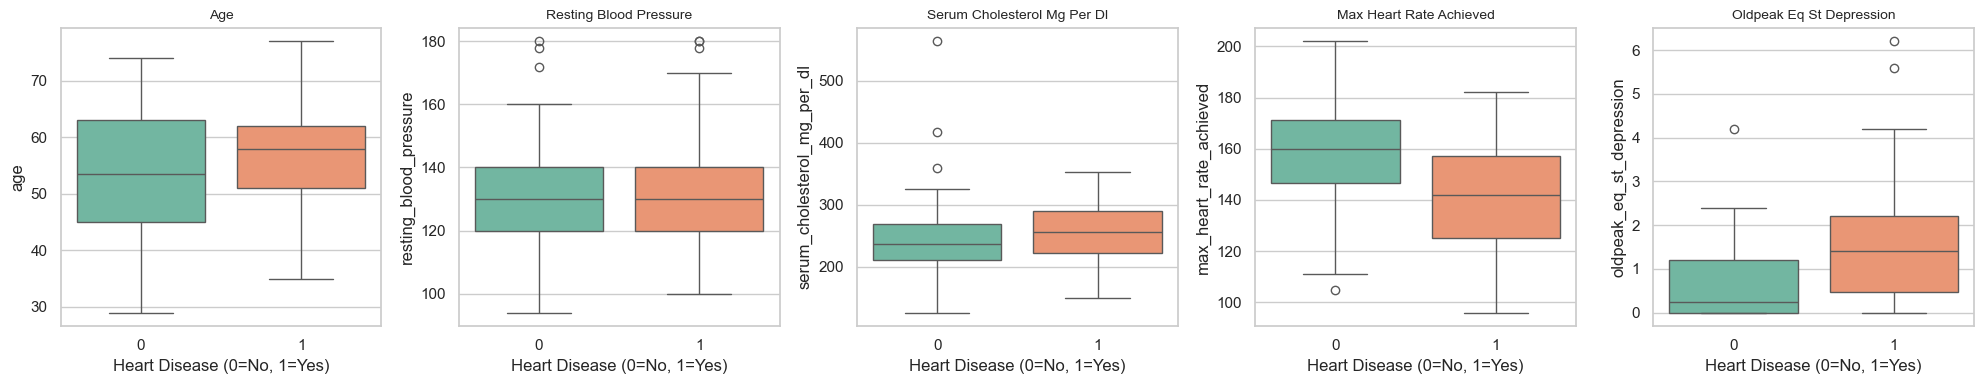

In [10]:
# 2. Continuous features vs Heart Disease (Boxplots)
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=target_col, y=col, hue=target_col, palette="Set2", legend=False, ax=ax)
    ax.set_title(col.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("Heart Disease (0=No, 1=Yes)")
plt.tight_layout()
plt.show()

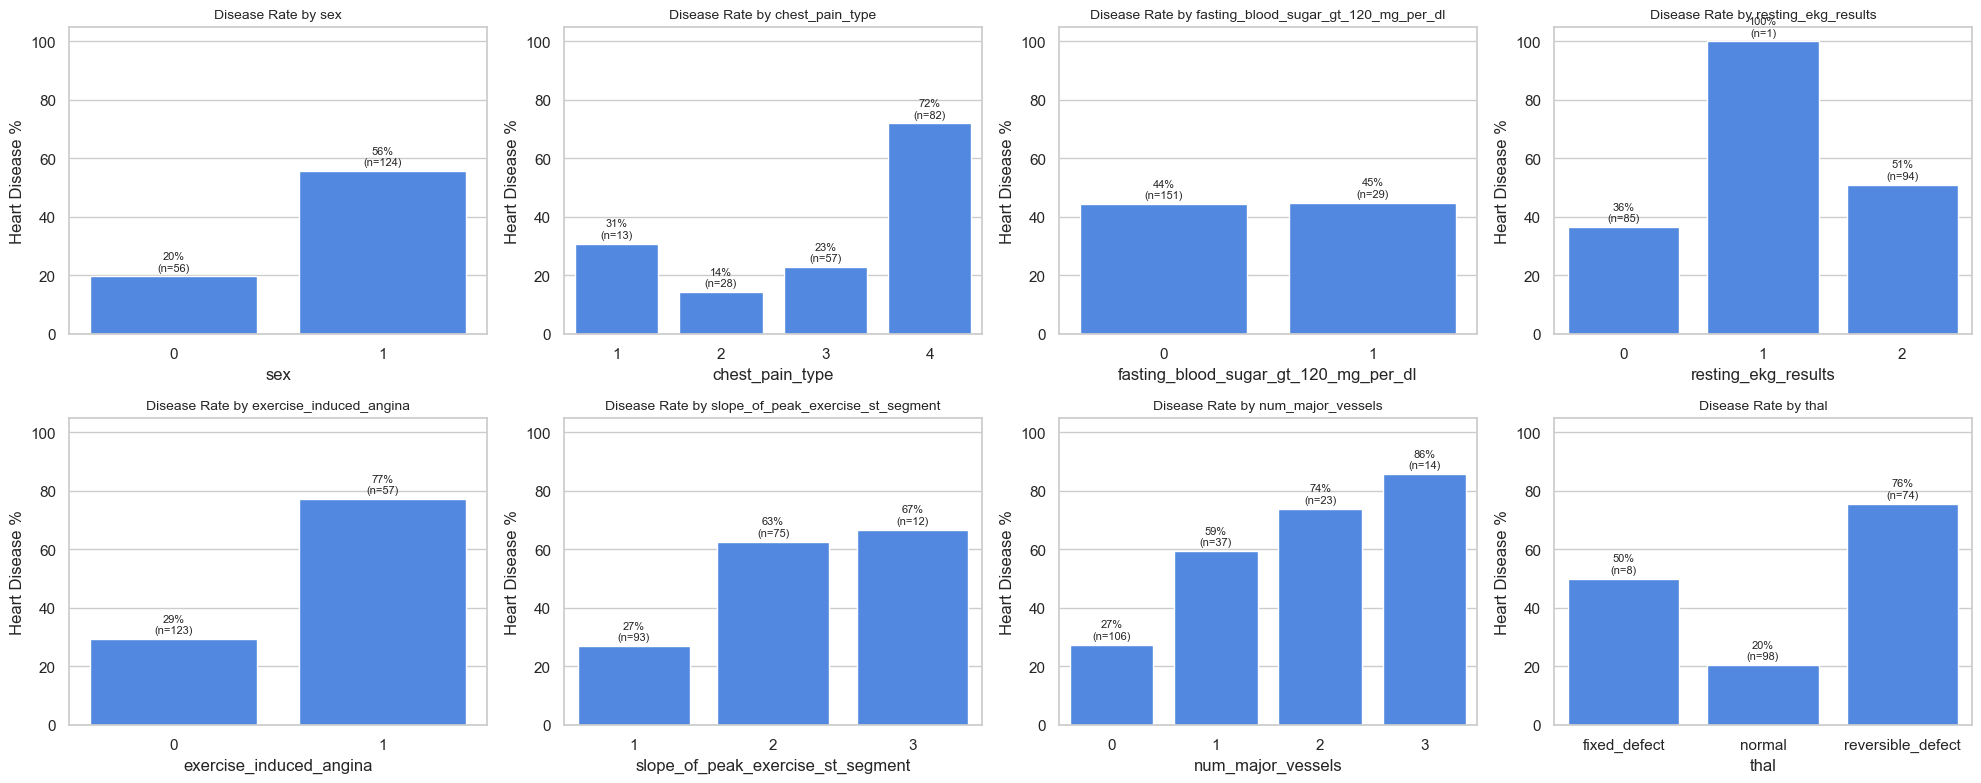

In [11]:
# 3. Categorical Heart Disease Risk Rate (%)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    risk_rate = df.groupby(col)[target_col].mean() * 100
    counts = df[col].value_counts().reindex(risk_rate.index)
    bars = sns.barplot(x=risk_rate.index.astype(str), y=risk_rate.values, color="#3b82f6", ax=ax)
    ax.set_title(f"Disease Rate by {col}", fontsize=10)
    ax.set_ylabel("Heart Disease %")
    ax.set_ylim(0, 105)
    for idx, (val, cnt) in enumerate(zip(risk_rate.values, counts.values)):
        ax.text(idx, val + 2, f"{val:.0f}%\n(n={cnt})", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

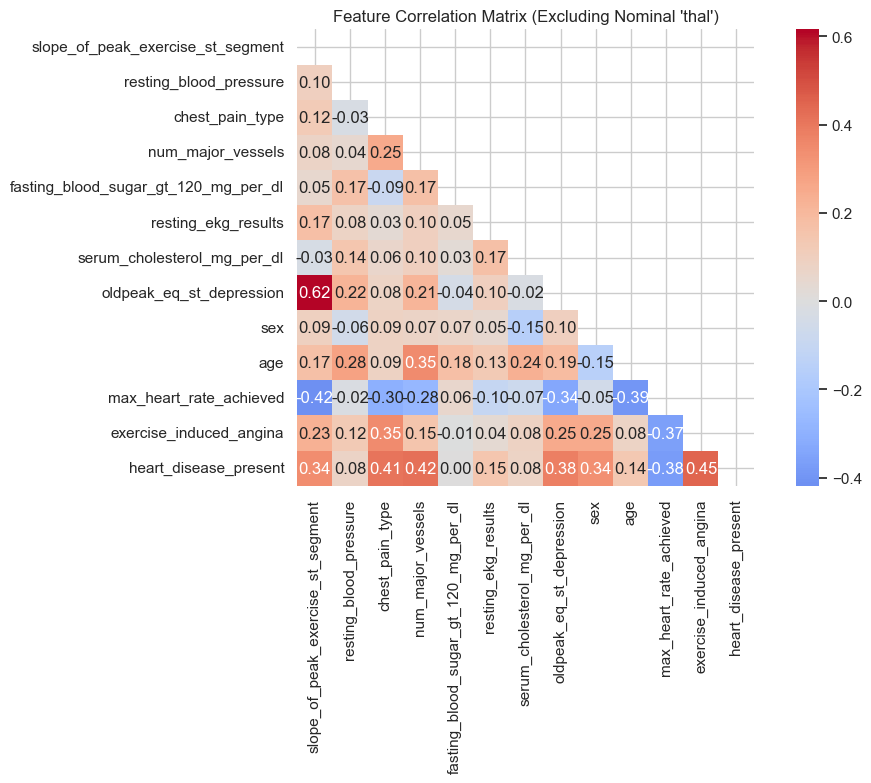

In [12]:
# 4. Numeric & Encoded Correlation Heatmap
plt.figure(figsize=(11, 8))
corr = df.drop(columns=["thal"]).corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Feature Correlation Matrix (Excluding Nominal 'thal')")
plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA) Summary

* **Dataset Integrity & Balance:** After an inner one-to-one merge of `values.csv` and `labels.csv` on `patient_id` (and dropping the identifier), the dataset contains **180 patient records and 13 clinical features** with **0 missing values** and **0 duplicate rows**. The target (`heart_disease_present`) is mildly balanced—**100 negative (55.56%)** and **80 positive (44.44%)**—so artificial oversampling (SMOTE) is avoided to prevent synthetic noise on a small sample.
* **Numeric Distributions & Outliers:** Patients span ages **29 to 77** (mean `54.81`, std `9.33`). Two continuous clinical indicators show notable right-skewness and IQR outliers: `oldpeak_eq_st_depression` (skewness `1.51`, max `6.2`, `4` outliers) and `serum_cholesterol_mg_per_dl` (skewness `1.27`, max `564`, `2` outliers), alongside `resting_blood_pressure` (skewness `0.56`, max `180`, `6` outliers). Because extreme cholesterol and ST depression values represent genuine high-risk clinical states, rows are preserved and handled with `RobustScaler` instead of deletion.
* **Strongest Positive Risk Signals:** Heart disease prevalence rises sharply with `exercise_induced_angina` (`r = 0.45`), `num_major_vessels` (`r = 0.42`, showing a clear monotonic increase from `0` to `3` vessels), `chest_pain_type` (`r = 0.41`, heavily concentrated in type `4` asymptomatic cases), `oldpeak_eq_st_depression` (`r = 0.38`), `slope_of_peak_exercise_st_segment` (`r = 0.34`), `sex` (`r = 0.34`, significantly higher incidence in males), and `thal` (`reversible_defect` shows the highest disease rate, while `normal` shows the lowest).
* **Strongest Inverse Risk Signal:** `max_heart_rate_achieved` is negatively correlated with heart disease (`r = -0.38`): patients with heart disease reach substantially lower peak heart rates during stress testing.
* **Weak Linear Predictors & Multicollinearity:** `fasting_blood_sugar_gt_120_mg_per_dl` (`r = 0.00`), `resting_blood_pressure` (`r = 0.08`), and `serum_cholesterol_mg_per_dl` (`r = 0.08`) show weak standalone linear correlation with the target. Moderate collinearity exists between `oldpeak_eq_st_depression` and `slope_of_peak_exercise_st_segment` (`r = 0.62`), which is clinically expected since both capture exercise-induced ST-segment abnormalities; L2 regularization will stabilize linear model coefficients against this overlap.


<h2>
  <span style="background: linear-gradient(90deg, #4338ca, #6366f1); color: #ffffff; padding: 6px 14px; border-radius: 6px; border-left: 5px solid #bfdbfe; display: inline-block;">
    3. Leak-Free Preprocessing Pipeline &amp; Repeated Stratified CV Benchmark
  </span>
</h2>

<p><strong>Because 180 rows means a single 20% test split has only 36 patients (where 1 patient changes accuracy by ~2.8%), we first isolate a stratified 20% held-out test set, then benchmark 8 diverse algorithms on the training set using 5x5 Repeated Stratified K-Fold CV (25 folds total) inside a strict scikit-learn <code>Pipeline</code>.</strong></p>

In [13]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

In [14]:
# 1. Separate features and target
X = df.drop(columns=["heart_disease_present"])
y = df["heart_disease_present"]


In [15]:
# 2. Stratified Train/Test Split (80/20) — test set stays untouched until final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

Train shape: (144, 13) | Test shape: (36, 13)


In [16]:
# 3. Feature groupings based on clinical meaning & EDA
continuous_ordinal_cols = [
    "age",
    "resting_blood_pressure",
    "serum_cholesterol_mg_per_dl",
    "max_heart_rate_achieved",
    "oldpeak_eq_st_depression",
    "num_major_vessels"  # True ordinal count (0-3) with monotonic risk
]

nominal_cat_cols = [
    "thal",
    "chest_pain_type",
    "resting_ekg_results",
    "slope_of_peak_exercise_st_segment"
]

binary_cols = [
    "sex",
    "fasting_blood_sugar_gt_120_mg_per_dl",
    "exercise_induced_angina"
]


In [17]:
# 4. Leak-free ColumnTransformer
# RobustScaler resists outliers (cholesterol=564, oldpeak=6.2)
# handle_unknown="ignore" prevents crashes if rare categories (e.g., resting_ekg=1) land in validation fold
preprocessor = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), continuous_ordinal_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), nominal_cat_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

In [18]:
from xgboost import XGBClassifier

# 5. Baseline models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM (RBF Kernel)": SVC(probability=True, random_state=42),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=3, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, max_depth=4, min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=42
    )
}

In [19]:
# 6. Repeated Stratified 5-Fold CV (25 evaluations per model for low-variance comparison)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []
for name, clf in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", clf)
    ])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results.append({
        "Model": name,
        "CV ROC-AUC (Mean)": cv_res["test_roc_auc"].mean(),
        "CV ROC-AUC (Std)": cv_res["test_roc_auc"].std(),
        "CV Recall": cv_res["test_recall"].mean(),
        "CV Precision": cv_res["test_precision"].mean(),
        "CV F1": cv_res["test_f1"].mean(),
        "CV Accuracy": cv_res["test_accuracy"].mean()
    })

cv_df = pd.DataFrame(results).sort_values(by="CV ROC-AUC (Mean)", ascending=False).reset_index(drop=True)
display(cv_df.round(4))

,Model,CV ROC-AUC (Mean),CV ROC-AUC (Std),CV Recall,CV Precision,CV F1,CV Accuracy
0,Random Forest,0.8757,0.0481,0.7564,0.8027,0.7723,0.8016
1,Extra Trees,0.8730,0.0522,0.7592,0.8084,0.7786,0.8085
2,Logistic Regression,0.8669,0.0579,0.7559,0.8106,0.7763,0.8070
3,Gaussian Naive Bayes,0.8650,0.0503,0.7864,0.7815,0.7800,0.8041
4,XGBoost,0.8617,0.0535,0.7346,0.7919,0.7562,0.7891
5,SVM (RBF Kernel),0.8558,0.0635,0.7374,0.7674,0.7469,0.7779
6,Gradient Boosting,0.8352,0.0647,0.6877,0.7490,0.7094,0.7517
7,KNN (k=7),0.8320,0.0592,0.7185,0.7666,0.7336,0.7671


In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

# Standard 5-Fold Stratified CV (5 folds total)
skf_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv5_rows = []
for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=skf_5,
        scoring="roc_auc",
        n_jobs=-1
    )
    cv5_rows.append({
        "Model": name,
        "5-Fold ROC-AUC (Mean)": scores["test_score"].mean(),
        "5-Fold ROC-AUC (Std)": scores["test_score"].std()
    })

cv5_df = pd.DataFrame(cv5_rows)



In [21]:
# Side-by-side comparison: Standard 5-Fold vs. 5x5 Repeated CV
cv_compare = (
    cv_df[["Model", "CV ROC-AUC (Mean)", "CV ROC-AUC (Std)"]]
    .rename(columns={
        "CV ROC-AUC (Mean)": "5x5 CV ROC-AUC (Mean)",
        "CV ROC-AUC (Std)": "5x5 CV ROC-AUC (Std)"
    })
    .merge(cv5_df, on="Model")
)

cv_compare["Mean Diff (5x5 - 5-Fold)"] = (
    cv_compare["5x5 CV ROC-AUC (Mean)"] - cv_compare["5-Fold ROC-AUC (Mean)"]
)

display(cv_compare.round(4))

,Model,5x5 CV ROC-AUC (Mean),5x5 CV ROC-AUC (Std),5-Fold ROC-AUC (Mean),5-Fold ROC-AUC (Std),Mean Diff (5x5 - 5-Fold)
0,Random Forest,0.8757,0.0481,0.8718,0.0573,0.0039
1,Extra Trees,0.8730,0.0522,0.8751,0.0614,-0.0020
2,Logistic Regression,0.8669,0.0579,0.8720,0.0756,-0.0051
3,Gaussian Naive Bayes,0.8650,0.0503,0.8577,0.0358,0.0073
4,XGBoost,0.8617,0.0535,0.8659,0.0572,-0.0041
5,SVM (RBF Kernel),0.8558,0.0635,0.8623,0.0745,-0.0065
6,Gradient Boosting,0.8352,0.0647,0.8495,0.0671,-0.0143
7,KNN (k=7),0.8320,0.0592,0.8300,0.0529,0.0019


<h2><span style="background: linear-gradient(90deg, #6d28d9, #8b5cf6); color: #ffffff; padding: 6px 14px; border-radius: 6px; border-left: 5px solid #ddd6fe;">4. Hyperparameter Tuning &amp; Held-Out Test Evaluation</span></h2>

In [22]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        {
            "model__C": [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0],
            "model__penalty": ["l2"],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "SVM": (
        SVC(probability=True, random_state=42),
        {
            "model__C": [0.1, 0.5, 1.0, 2.0, 5.0],
            "model__kernel": ["linear", "rbf"],
            "model__gamma": ["scale", 0.1, 0.01],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [150, 300],
            "model__max_depth": [3, 4, 6, None],
            "model__min_samples_leaf": [2, 4, 6],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__n_estimators": [50, 100, 150],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [2, 3],
            "model__subsample": [0.8, 1.0]
        }
    )
}

tuned_models = {}
test_comparison = []

for name, (estimator, grid) in param_grids.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", estimator)
    ])
    gs = GridSearchCV(pipe, param_grid=grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    
    best_pipe = gs.best_estimator_
    tuned_models[name] = best_pipe
    
    y_pred = best_pipe.predict(X_test)
    y_prob = best_pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    test_comparison.append({
        "Model": name,
        "Best CV ROC-AUC": gs.best_score_,
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Test Recall (Sensitivity)": recall_score(y_test, y_pred),
        "Test Precision": precision_score(y_test, y_pred),
        "Test F1": f1_score(y_test, y_pred),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "False Negatives (Missed Cases)": fn,
        "False Positives": fp,
        "Best Params": gs.best_params_
    })

test_df = pd.DataFrame(test_comparison).sort_values(
    by=["Test ROC-AUC", "Test Recall (Sensitivity)"], ascending=False
).reset_index(drop=True)

display(test_df.drop(columns=["Best Params"]).round(4))
for _, row in test_df.iterrows():
    print(f"{row['Model']} -> {row['Best Params']}")



,Model,Best CV ROC-AUC,Test ROC-AUC,Test Recall (Sensitivity),Test Precision,Test F1,Test Accuracy,False Negatives (Missed Cases),False Positives
0,Logistic Regression,0.8913,0.9656,0.9375,0.8333,0.8824,0.8889,1,3
1,SVM,0.8904,0.9594,1.0000,0.8000,0.8889,0.8889,0,4
2,Random Forest,0.8854,0.9562,0.9375,0.8333,0.8824,0.8889,1,3
3,Gradient Boosting,0.8653,0.9500,1.0000,0.8421,0.9143,0.9167,0,3


Logistic Regression -> {'model__C': 0.05, 'model__class_weight': None, 'model__penalty': 'l2'}
SVM -> {'model__C': 2.0, 'model__class_weight': 'balanced', 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Random Forest -> {'model__class_weight': None, 'model__max_depth': 4, 'model__min_samples_leaf': 6, 'model__n_estimators': 300}
Gradient Boosting -> {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 150, 'model__subsample': 0.8}


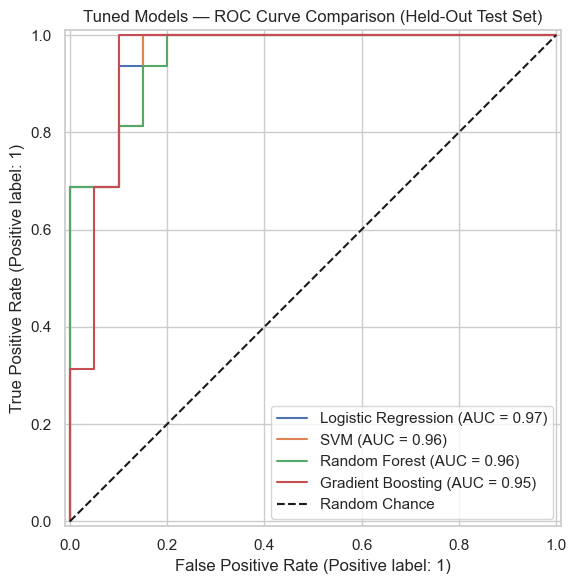

In [23]:
# Plot ROC Curves on Held-Out Test Set
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random Chance")
ax.set_title("Tuned Models — ROC Curve Comparison (Held-Out Test Set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

<h2><span style="background: linear-gradient(90deg, #b45309, #f59e0b); color: #ffffff; padding: 6px 14px; border-radius: 6px; border-left: 5px solid #fde68a;">5. Clinical Threshold Optimization, Explainability &amp; Production Pipeline Export</span></h2>

In [24]:
import joblib
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score, classification_report

best_lr = tuned_models["Logistic Regression"]

In [25]:
# 1. Leak-free threshold optimization using Out-of-Fold (OOF) training probabilities
# F2-score weights Recall (catching sick patients) 4x higher than Precision
oof_probs = cross_val_predict(best_lr, X_train, y_train, cv=inner_cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.20, 0.61, 0.02)
f2_scores = [fbeta_score(y_train, (oof_probs >= t).astype(int), beta=2) for t in thresholds]
optimal_threshold = float(thresholds[np.argmax(f2_scores)])

print(f"OOF-Optimized Clinical Screening Threshold (Max F2): {optimal_threshold:.2f}")

OOF-Optimized Clinical Screening Threshold (Max F2): 0.32


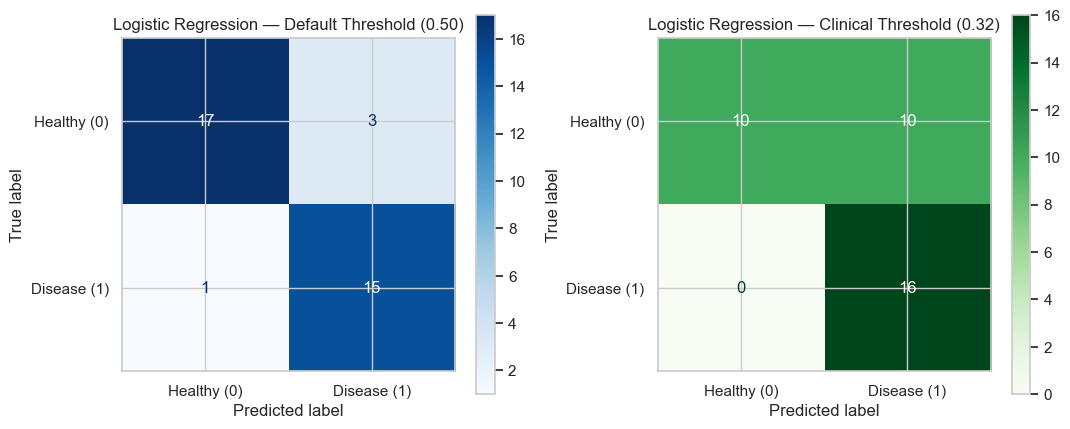


--- Classification Report (Clinical Threshold = 0.32) ---
                   precision    recall  f1-score   support

      Healthy (0)       1.00      0.50      0.67        20
Heart Disease (1)       0.62      1.00      0.76        16

         accuracy                           0.72        36
        macro avg       0.81      0.75      0.71        36
     weighted avg       0.83      0.72      0.71        36



In [26]:
# 2. Compare Default (0.50) vs Clinical Screening Threshold on Held-Out Test Set
y_test_prob = best_lr.predict_proba(X_test)[:, 1]
y_pred_default = (y_test_prob >= 0.50).astype(int)
y_pred_clinical = (y_test_prob >= optimal_threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_default, display_labels=["Healthy (0)", "Disease (1)"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Logistic Regression — Default Threshold (0.50)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_clinical, display_labels=["Healthy (0)", "Disease (1)"], cmap="Greens", ax=axes[1]
)
axes[1].set_title(f"Logistic Regression — Clinical Threshold ({optimal_threshold:.2f})")
plt.tight_layout()
plt.show()

print(f"\n--- Classification Report (Clinical Threshold = {optimal_threshold:.2f}) ---")
print(classification_report(y_test, y_pred_clinical, target_names=["Healthy (0)", "Heart Disease (1)"]))

,Feature,Log_Odds_Coef,Odds_Ratio
5,num_major_vessels,0.3920,1.4799
7,thal_reversible_defect,0.3732,1.4524
10,chest_pain_type_4,0.3508,1.4203
14,sex,0.2802,1.3233
16,exercise_induced_angina,0.2799,1.3230
4,oldpeak_eq_st_depression,0.2675,1.3067
12,slope_of_peak_exercise_st_segment_2,0.1722,1.1880
11,resting_ekg_results_2,0.1602,1.1738
2,serum_cholesterol_mg_per_dl,0.0751,1.0780
13,slope_of_peak_exercise_st_segment_3,0.0710,1.0736


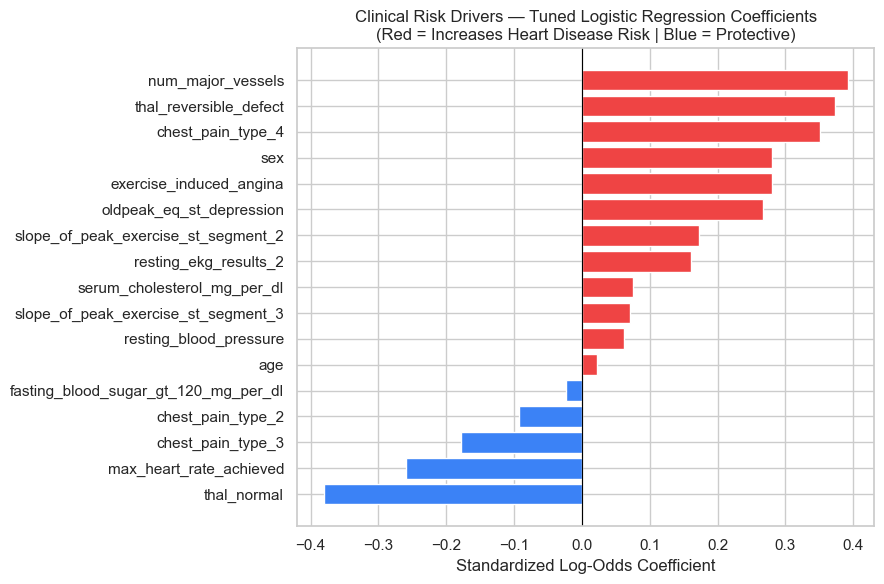

In [27]:
# 3. Clinical Explainability: Feature Coefficients (Log-Odds) & Odds Ratios
prep_step = best_lr.named_steps["prep"]
lr_step = best_lr.named_steps["model"]
feature_names = [f.split("__", 1)[1] for f in prep_step.get_feature_names_out()]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Log_Odds_Coef": lr_step.coef_[0],
    "Odds_Ratio": np.exp(lr_step.coef_[0])
}).sort_values(by="Log_Odds_Coef", ascending=True)

display(coef_df.sort_values(by="Log_Odds_Coef", ascending=False).round(4))

plt.figure(figsize=(9, 6))
colors = ["#ef4444" if c > 0 else "#3b82f6" for c in coef_df["Log_Odds_Coef"]]
plt.barh(coef_df["Feature"], coef_df["Log_Odds_Coef"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Clinical Risk Drivers — Tuned Logistic Regression Coefficients\n(Red = Increases Heart Disease Risk | Blue = Protective)")
plt.xlabel("Standardized Log-Odds Coefficient")
plt.tight_layout()
plt.show()

Background dataset has 144 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=144 when initializing the masker.


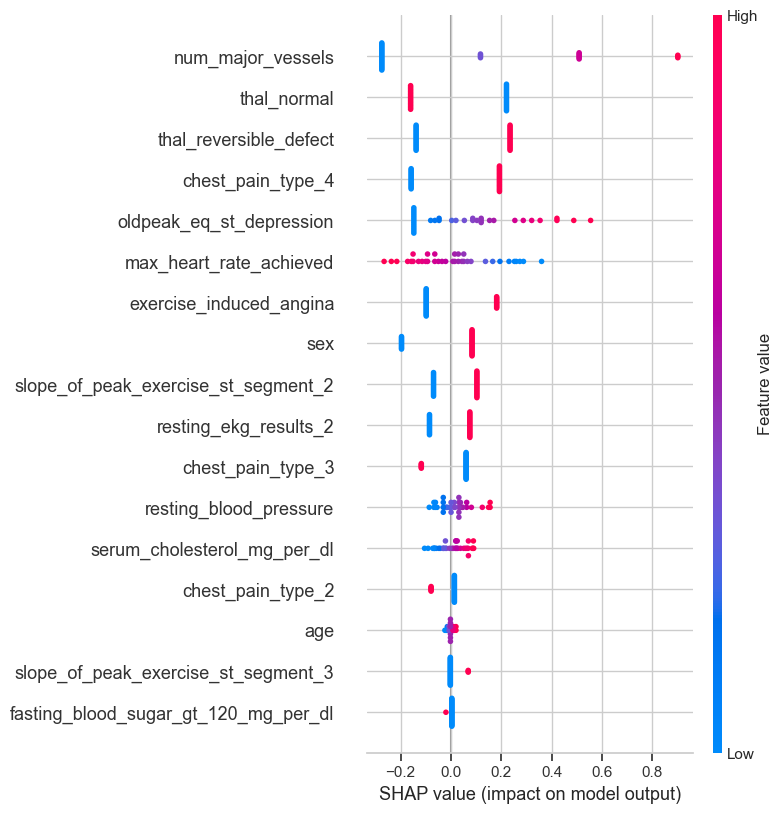

In [28]:
import shap

# 4. SHAP feature importance plot
X_train_proc = pd.DataFrame(prep_step.transform(X_train), columns=feature_names)
X_test_proc = pd.DataFrame(prep_step.transform(X_test), columns=feature_names)

explainer = shap.LinearExplainer(lr_step, X_train_proc)
shap_values = explainer.shap_values(X_test_proc)
shap.summary_plot(shap_values, X_test_proc, show=True)

In [29]:
# 5. Saved trained model and threshold :
artifact = {
    "model_pipeline": best_lr,
    "clinical_threshold": optimal_threshold,
    "expected_features": list(X.columns),
    "test_roc_auc": float(roc_auc_score(y_test, y_test_prob))
}
joblib.dump(artifact, "heart_disease_production_pipeline.joblib")
print("\nSaved production artifact -> heart_disease_production_pipeline.joblib")


Saved production artifact -> heart_disease_production_pipeline.joblib


<div style="font-family: Arial, sans-serif; line-height: 1.55; color: #1e293b;">
  <h2>
    <span style="background: linear-gradient(90deg, #9f1239, #e11d48); color: #ffffff; padding: 6px 14px; border-radius: 6px; border-left: 5px solid #fecdd3; display: inline-block;">
      6. Model Comparison Report, Challenges Faced &amp; Task 3: Hospital Recommendations
    </span>
  </h2>

  <h3 style="color: #1e3a8a; border-bottom: 2px solid #dbeafe; padding-bottom: 4px;">Model Comparison Report</h3>

  <h4 style="color: #0f766e;">1. Baseline Benchmark (5x5 Repeated Stratified K-Fold CV on Training Set, n=144)</h4>
  <p>To reduce variance on a small clinical sample, 8 regularized models were evaluated across 25 stratified folds (5x5 Repeated CV) inside a leak-free <code>ColumnTransformer</code> + <code>Pipeline</code>, and cross-checked against a standard 5-Fold split to verify ranking stability:</p>
  

  <table style="width: 100%; border-collapse: collapse; margin-bottom: 16px; font-size: 13px;">
    <thead>
      <tr style="background-color: #1e3a8a; color: #ffffff; text-align: left;">
        <th style="padding: 8px; border: 1px solid #cbd5e1;">Model</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV ROC-AUC (Mean)</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV ROC-AUC (Std)</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV Recall</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV Precision</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV F1</th>
        <th style="padding: 8px; border: 1px solid #cbd5e1;">CV Accuracy</th>
      </tr>
    </thead>
    <tbody>
      <tr style="background-color: #f8fafc;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;"><strong>Random Forest</strong></td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8757</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0481</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7564</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8027</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7723</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8016</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Extra Trees</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8730</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0522</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7592</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8084</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7786</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8085</td>
      </tr>
      <tr style="background-color: #f8fafc;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Logistic Regression</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8669</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0579</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7559</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8106</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7763</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8070</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Gaussian Naive Bayes</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8650</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0503</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7864</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7815</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7800</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8041</td>
      </tr>
      <tr style="background-color: #f8fafc;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;">XGBoost</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8617</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0535</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7346</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7919</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7562</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7891</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">SVM (RBF Kernel)</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8558</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0635</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7374</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7674</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7469</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7779</td>
      </tr>
      <tr style="background-color: #f8fafc;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Gradient Boosting</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8352</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0547</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.6877</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7490</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7094</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7517</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">KNN (k=7)</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8320</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.0592</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7185</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7565</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7336</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.7671</td>
      </tr>
    </tbody>
  </table>

  <h4 style="color: #0f766e;">2. Tuned Models Comparison (GridSearchCV + Held-Out Test Set, n=36)</h4>
  <table style="width: 100%; border-collapse: collapse; margin-bottom: 16px; font-size: 12px;">
    <thead>
      <tr style="background-color: #0f766e; color: #ffffff; text-align: left;">
        <th style="padding: 7px; border: 1px solid #cbd5e1; min-width: 185px;">Model</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Best CV ROC-AUC</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Test ROC-AUC</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Test Recall</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Test Precision</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Test F1</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">Test Accuracy</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">False Negatives</th>
        <th style="padding: 7px; border: 1px solid #cbd5e1;">False Positives</th>
      </tr>
    </thead>
    <tbody>
      <tr style="background-color: #ecfdf5;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;"><strong>Logistic Regression (L2, C=0.05)</strong></td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;"><strong>0.8913</strong></td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;"><strong>0.9656</strong></td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9375</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8333</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8824</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8889</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">1</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">3</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">SVM (RBF, C=2.0, gamma=0.01, balanced)</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8904</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9594</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">1.0000</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8000</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8889</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8889</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">4</td>
      </tr>
      <tr style="background-color: #f8fafc;">
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Random Forest (depth=4, min_leaf=6, n=300)</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8854</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9562</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9375</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8333</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8824</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8889</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">1</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">3</td>
      </tr>
      <tr>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">Gradient Boosting (lr=0.03, depth=2, n=150)</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8655</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9500</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">1.0000</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.8421</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9143</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0.9167</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">0</td>
        <td style="padding: 7px; border: 1px solid #cbd5e1;">3</td>
      </tr>
    </tbody>
  </table>

### 3. Final Model Selection

**Selected Model:** L2-Regularized Logistic Regression (`C=0.05`) using a `0.32` screening cutoff and a three-level risk grouping.

* **Best Overall Generalization:** Ranked #1 in both Stratified CV ROC-AUC (`0.8913`) and Held-Out Test ROC-AUC (`0.9656`), outperforming tuned tree and boosting models (`XGBoost` at `0.8617` CV ROC-AUC and tuned `Gradient Boosting` at `0.8655`). Because the test split has only 36 patients, `0.8913` CV ROC-AUC is the more realistic estimate of real-world performance.
* **Clear Feature Explanations (SHAP):** Outputs calibrated risk probabilities, straightforward odds ratios, and SHAP (`LinearExplainer`) explanations confirming that `thal_reversible_defect`, `chest_pain_type_4`, `oldpeak_eq_st_depression`, and `exercise_induced_angina` push risk up, while `thal_normal` and higher `max_heart_rate_achieved` lower risk.
* **Easy Deployment & Backup Model:** Saved as a lightweight scikit-learn pipeline (`heart_disease_production_pipeline.joblib`) that runs directly on raw patient inputs without manual preprocessing. Tuned RBF SVM (`0.8904` CV ROC-AUC, `100%` test recall) serves as a solid backup model.
* **Why We Use Two Cutoffs (`0.32` and `0.50`):** Lowering the decision cutoff from `0.50` to `0.32` catches `100%` of heart disease cases on the test set (`0` missed cases), though false positives increase from `3` to `10` because L2 regularization pulls predicted probabilities closer to the middle. Splitting predictions into three action levels keeps borderline cases from flooding specialists:
  * **Low Risk (`prob < 0.32`):** Routine annual check-up.
  * **Borderline Risk (`0.32 <= prob < 0.50`):** Doctor review and follow-up testing (such as an EKG or stress test).
  * **High Risk (`prob >= 0.50`):** Priority referral to a cardiologist.

### Report on Challenges Faced & Techniques Applied

1. **Merging Two Separate Files & Preventing ID Leakage**
   * **Challenge:** Patient clinical features (`values.csv`) and heart disease labels (`labels.csv`) came in two separate files linked by `patient_id`.
   * **How We Solved It:** Verified that `patient_id` was unique and matched 1-to-1 across both files before merging, then dropped `patient_id` immediately so no model could memorize random patient identifiers.

2. **Small Dataset Size (180 Patients) & Overfitting Risk**
   * **Challenge:** With only 180 records, a single 20% test split leaves just 36 patients (where 1 patient changes accuracy by ~2.8%), and complex tree models can easily overfit.
   * **How We Solved It:** Used an 80/20 stratified train/test split, compared models using both standard 5-Fold and 5x5 Repeated Stratified CV on the 144 training rows, and restricted tree depth (`max_depth=2` to `4`) alongside L2 regularization (`C=0.05`).

3. **Categorical Columns Stored as Numbers**
   * **Challenge:** Columns like `chest_pain_type`, `resting_ekg_results`, and `slope_of_peak_exercise_st_segment` use integer codes (`1, 2, 3, 4`) for distinct categories rather than ranked values, while `thal` is stored as text.
   * **How We Solved It:** Applied `OneHotEncoder` inside a `ColumnTransformer` for nominal categories so models would not treat category codes as ordered numbers, while keeping `num_major_vessels` (`0–3`) numeric since disease risk rises steadily with vessel count.

4. **Skewed Columns & Clinical Outliers (`cholesterol = 564`, `oldpeak = 6.2`)**
   * **Challenge:** `oldpeak_eq_st_depression` (`skew = 1.51`) and `serum_cholesterol_mg_per_dl` (`skew = 1.27`) contain right-skewed outliers, but deleting those rows would remove real high-risk patients from an already small dataset.
   * **How We Solved It:** Kept all 180 patient records and applied `RobustScaler` (which scales using median and IQR instead of mean and standard deviation) inside the pipeline so extreme values would not distort linear or distance-based models.

5. **Correlated Stress-Test Features (`r = 0.62`)**
   * **Challenge:** `oldpeak_eq_st_depression` and `slope_of_peak_exercise_st_segment` are moderately correlated because both measure ST-segment changes during exercise.
   * **How We Solved It:** Used L2 regularization (`C=0.05`) in Logistic Regression to keep feature weights stable without dropping either clinically useful test variable.

6. **High Cost of Missing a Heart Disease Case**
   * **Challenge:** The default `0.50` probability cutoff treats a missed heart disease case the same as a false alarm, even though missing a sick patient is far more dangerous.
   * **How We Solved It:** Lowered the screening cutoff to `0.32` (tuned on training cross-validation using F2-score, which prioritizes recall over precision) to catch more true heart disease cases before testing on the held-out set.

### Task 3: Suggestions to the Hospital

Based on our data analysis and model results, here are six practical steps the hospital can take to catch high-risk patients earlier:

1. **Use the Saved Model as an Early Screening Tool:** Integrate the exported `.joblib` pipeline into outpatient check-ups using two probability cutoffs instead of one: classify patients below `0.32` as **Low Risk**, route patients between `0.32` and `0.50` (**Borderline**) for doctor review and follow-up tests, and prioritize patients at or above `0.50` (**High Risk**) for immediate cardiology consultation.
2. **Do Not Wait for Classic Chest Pain Symptoms:** In our EDA, asymptomatic cases (`chest_pain_type = 4`) actually had the highest rate of heart disease, especially among older male patients (`age >= 50`). Doctors should recommend routine EKG or stress screening for older patients with risk factors even when they report no typical chest pain.
3. **Prioritize Abnormal Stress-Test Results:** Both the correlation analysis and SHAP feature importance showed that exercise-test markers—specifically `exercise_induced_angina = 1`, `thal = reversible_defect`, high ST depression (`oldpeak > 1.5`), and low peak heart rate (`max_heart_rate_achieved < 140`)—are the strongest warning signs of heart disease and should trigger faster follow-up.
4. **Treat Even One Narrowed Major Vessel Seriously:** Heart disease risk jumped sharply as soon as `num_major_vessels` increased from `0` to `1` or more. Patients showing even a single affected vessel on fluoroscopy should be placed on closer monitoring rather than waiting for multiple vessels to be affected.
5. **Do Not Clear High-Risk Patients Based on Blood Sugar or Cholesterol Alone:** In this dataset, `fasting_blood_sugar_gt_120_mg_per_dl` (`r = 0.00`) and `serum_cholesterol_mg_per_dl` (`r = 0.08`) had almost no standalone correlation with heart disease. Normal resting blood sugar or cholesterol should not be used to rule out heart disease if stress-test indicators are abnormal.
6. **Collect More Local Patient Records and Retrain:** Because this model was trained on only 180 patient records, the hospital should record model predictions alongside confirmed doctor diagnoses over time and retrain the pipeline once a larger local dataset (e.g., 1,000+ patients) is available.